# Recruitment Data Detective — Before vs After Evaluation
**ZEIL Hackathon 2026 | Prompt Engineering & Agent Reliability**

**Objective.** Compare baseline and structured investigation prompts under the same model (`gemini-flash-latest`), temperature (0.2), Python toolset, and synthetic recruitment scenarios. This notebook runs with the **one provided paired example** (`high_conversion`) and optionally imports all cases from `eval_results/paired_raw.json` or `eval_results/before_after.json` if those files are present.

**Critical interpretation:** A `PASS` in the original harness verifies tool invocation, agreement with a *deterministic Python bottleneck rule*, and nonempty report text. It **does not** independently verify every generated sentence, nor establish statistically significant model improvement.

## 1. Experimental design and assumptions

- **Baseline:** less prescriptive investigation prompt.
- **Improved:** explicit evidence collection, `REVIEW` / `LOW_SAMPLE` / `OK` classification, hypotheses, follow-ups and self-check steps.
- **Control:** same scenarios, model, tools, sampling temperature and scoring code.
- **Detector definition:** flag a stage conversion **strictly below 30%** if the previous stage has **at least 10** candidates. This is a demo rule, **not a validated recruitment benchmark**.
- **Infrastructure errors:** track `429/503` separately from logical failures.
- **Reproducibility limitation:** stochastic responses and service demand vary across runs; one response per prompt per case does not isolate all randomness.


In [4]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()

print('Notebook working directory:', ROOT)


Notebook working directory: /Users/vicmon/ZEIL


## 2. Load evaluation records

The two reports supplied in chat are embedded as a compact **verified evidence summary**, not fabricated full tool logs. If a real paired result file is found, it takes precedence for quantitative metrics. The notebook intentionally does not invent missing records.

In [5]:
# The supplied matched case (both prompts passed original checks).
provided_pair = [
    {'case': 'high_conversion', 'version': 'baseline', 'expected_flag': False,
     'actual_flag': False, 'tool_used': True, 'detector_used': True,
     'report_generated': True, 'status': 'PASS', 'error': None},
    {'case': 'high_conversion', 'version': 'improved', 'expected_flag': False,
     'actual_flag': False, 'tool_used': True, 'detector_used': True,
     'report_generated': True, 'status': 'PASS', 'error': None},
]

candidates = [
    ROOT / 'eval_results' / 'before_after.json',
    ROOT / 'eval_results' / 'paired_raw.json',
    ROOT.parent / 'eval_results' / 'before_after.json',
    ROOT.parent / 'eval_results' / 'paired_raw.json',
]
records = provided_pair
source = 'Embedded high_conversion paired example (2 records)'
for path in candidates:
    if path.exists():
        try:
            raw = json.loads(path.read_text(encoding='utf-8'))
            loaded = raw['results'] if isinstance(raw, dict) else raw
            if isinstance(loaded, list) and loaded and all(
                isinstance(x, dict) and 'case' in x and 'version' in x
                for x in loaded
            ):
                records, source = loaded, str(path)
                break
        except (ValueError, OSError, TypeError, KeyError) as exc:
            print(f'Skipping {path}: {exc}')

print('Data source:', source)
df = pd.DataFrame(records)
display(df[[c for c in ['case','version','status','tool_used','detector_used','actual_flag','expected_flag','report_generated'] if c in df]])


Data source: /Users/vicmon/ZEIL/eval_results/before_after.json


,case,version,status,tool_used,detector_used,actual_flag,expected_flag,report_generated
0,normal,baseline,PASS,True,True,False,False,True
1,normal,improved,PASS,True,True,False,False,True
2,screening_drop,baseline,PASS,True,True,True,True,True
3,screening_drop,improved,PASS,True,True,True,True,True
4,high_conversion,baseline,PASS,True,True,False,False,True
5,high_conversion,improved,PASS,True,True,False,False,True
6,zero_interviews,baseline,PASS,True,True,True,True,True
7,zero_interviews,improved,PASS,True,True,True,True,True
8,low_offers,baseline,PASS,True,True,True,True,True
9,low_offers,improved,PASS,True,True,True,True,True


## 3. Quantitative evaluation

Report **end-to-end success** (all attempted requests) separately from **conditional pass rate** (only completed requests). Neither metric should be labeled anomaly *prediction accuracy*, since `actual_flag` comes from a deterministic Python tool.

In [6]:
rows=[]
for version, group in df.groupby('version', sort=False):
    state = group['status'].fillna('FAIL')
    passed = int((state == 'PASS').sum())
    failed = int((state == 'FAIL').sum())
    api_errors = int((state == 'API_ERROR').sum())
    completed = passed + failed
    rows.append({
        'Prompt': version,
        'Cases attempted': len(group),
        'Passed': passed,
        'Logic failures': failed,
        'API errors': api_errors,
        'End-to-end success (%)': round(100*passed/len(group),1),
        'Pass among completed (%)': round(100*passed/completed,1) if completed else float('nan'),
        'Detector calls': int(group['detector_used'].fillna(False).astype(bool).sum()) if 'detector_used' in group else None,
    })
summary = pd.DataFrame(rows)
display(summary)


,Prompt,Cases attempted,Passed,Logic failures,API errors,End-to-end success (%),Pass among completed (%),Detector calls
0,baseline,7,7,0,0,100.0,100.0,7
1,improved,7,7,0,0,100.0,100.0,7


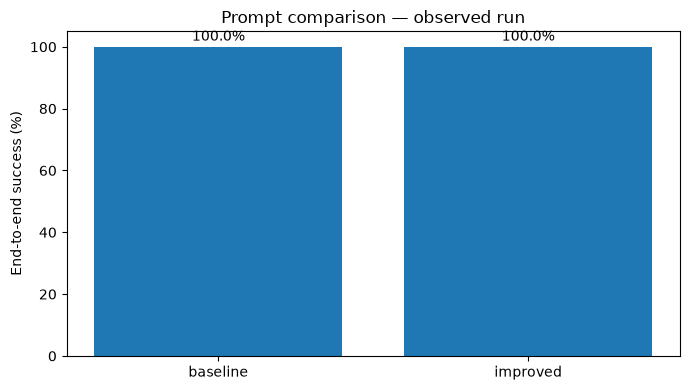

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(summary['Prompt'], summary['End-to-end success (%)'])
ax.set_ylim(0, 105)
ax.set_ylabel('End-to-end success (%)')
ax.set_title('Prompt comparison — observed run')
for i, v in enumerate(summary['End-to-end success (%)']):
    ax.text(i, min(v+2,102), f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()


### Paired outcomes

Comparisons should be based on cases where **both prompt variants were attempted**. Exclude pairs with `API_ERROR` when discussing conditional model behavior, but retain those errors in the operational reliability summary.

In [8]:
wide = df.pivot_table(index='case', columns='version', values='status', aggfunc='first')
display(wide.reset_index())
if {'baseline','improved'}.issubset(wide.columns):
    both_completed = wide[wide['baseline'].isin(['PASS','FAIL']) & wide['improved'].isin(['PASS','FAIL'])]
    improve = int(((both_completed['baseline']=='FAIL') & (both_completed['improved']=='PASS')).sum())
    regress = int(((both_completed['baseline']=='PASS') & (both_completed['improved']=='FAIL')).sum())
    print('Matched completed pairs:', len(both_completed))
    print('FAIL→PASS:', improve, '| PASS→FAIL:', regress)
else:
    print('Not enough paired records for comparison.')


version,case,baseline,improved
0,boundary_29,PASS,PASS
1,high_conversion,PASS,PASS
2,low_hiring,PASS,PASS
3,low_offers,PASS,PASS
4,normal,PASS,PASS
5,screening_drop,PASS,PASS
6,zero_interviews,PASS,PASS


Matched completed pairs: 7
FAIL→PASS: 0 | PASS→FAIL: 0


## 4. Case study — `high_conversion`

**Ground truth from synthetic cumulative counts:** `[60 applied, 55 screened, 45 interviewed, 30 offered, 20 hired]`.

| Stage transition | Calculation | Conversion | Expected status |
|---|---:|---:|---|
| Applied → Screened | 55 / 60 | 91.67% | OK |
| Screened → Interviewed | 45 / 55 | 81.82% | OK |
| Interviewed → Offered | 30 / 45 | 66.67% | OK |
| Offered → Hired | 20 / 30 | 66.67% | OK |

**Observed:** both responses reported these numbers correctly and returned the expected `False` bottleneck flag; both earned `PASS` under the existing harness.

**Qualitative differences in the supplied report text:**

| Dimension | Baseline | Improved |
|---|---|---|
| Stage-level evidence | Full table and counts | Full table and counts |
| Observation vs hypothesis | Separated | Explicit *Unverified Hypothesis* tags |
| Rule explanation | Included | Defines REVIEW / LOW_SAMPLE / OK explicitly |
| Method limitation | Notes lack of comparison data | Explains that `OK` does **not** prove a healthy hiring process |
| Recommended actions | Three | Three |
| Numerical correctness (reviewed metrics) | Correct | Correct |

**Substantive concern present in both:** the reports describe the 10 candidates who did not progress from offer to hire as *offer declines* / *unaccepted offers*. The data records only stage progression, not why a candidate did not progress. Thus **offer decline is an unverified hypothesis**, not an observed fact. The improved report labels hypotheses more explicitly, but its follow-up recommendation still presumes an offer-decline cohort.

**Other concern:** average `days_in_process = 17.5` is a candidate-level average of the synthetic field, not stage-specific duration or a causal explanation. Averages alone cannot locate delays between stages.

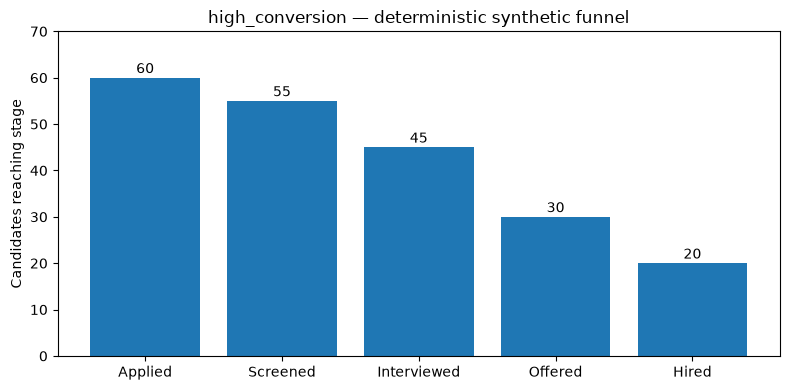

Transition conversions: ['91.67%', '81.82%', '66.67%', '66.67%']


In [9]:
counts = [60,55,45,30,20]
stages = ['Applied','Screened','Interviewed','Offered','Hired']
conversions = [100*counts[i+1]/counts[i] for i in range(4)]
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(stages, counts)
ax.set_ylabel('Candidates reaching stage')
ax.set_title('high_conversion — deterministic synthetic funnel')
for i, c in enumerate(counts):
    ax.text(i, c+1, str(c), ha='center')
ax.set_ylim(0, 70)
plt.tight_layout()
plt.show()
print('Transition conversions:', [f'{x:.2f}%' for x in conversions])


## 5. Stronger evaluation rubric (recommended)

The original harness mainly checks tool use and detector agreement. For a more credible **AI quality evaluation**, audit each saved `report` against the tool output using the same scoring rubric for both prompts:

- **Tool-use compliance (0/1):** `find_bottlenecks` called.
- **Classification correctness (0/1):** statuses agree with deterministic evidence.
- **Numeric fidelity (0/1):** all checked numbers consistent with the returned tool outputs.
- **Epistemic calibration (0/1):** does not treat hypotheses (e.g., offer declines or discrimination) as established facts.
- **Usable actions (0/1):** includes specific next steps supported by findings.

A human reviewer can use the worksheet below to score the reports. Blank = **unreviewed**, not zero. For full 10-case evaluation, score each case; keep the report text as audit evidence.

In [10]:
worksheet = df[['case','version']].copy()
for field in ['numeric_fidelity','epistemic_calibration','actionability']:
    worksheet[field] = pd.NA
worksheet['reviewer_notes'] = ''
# Known issue demonstrated by the supplied high_conversion text; do not automatically
# generalize this observation to all cases or convert it into a full scored evaluation.
display(worksheet)
print('Review worksheet created in memory. Use the next cell to export it.')


,case,version,numeric_fidelity,epistemic_calibration,actionability,reviewer_notes
0,normal,baseline,<NA>,<NA>,<NA>,
1,normal,improved,<NA>,<NA>,<NA>,
2,screening_drop,baseline,<NA>,<NA>,<NA>,
3,screening_drop,improved,<NA>,<NA>,<NA>,
4,high_conversion,baseline,<NA>,<NA>,<NA>,
5,high_conversion,improved,<NA>,<NA>,<NA>,
6,zero_interviews,baseline,<NA>,<NA>,<NA>,
7,zero_interviews,improved,<NA>,<NA>,<NA>,
8,low_offers,baseline,<NA>,<NA>,<NA>,
9,low_offers,improved,<NA>,<NA>,<NA>,


Review worksheet created in memory. Use the next cell to export it.


In [11]:
OUT = ROOT / 'eval_results'
OUT.mkdir(exist_ok=True)
worksheet_path = OUT / 'manual_review_worksheet.csv'
worksheet.to_csv(worksheet_path, index=False)
print('Saved:', worksheet_path)


Saved: /Users/vicmon/ZEIL/eval_results/manual_review_worksheet.csv


## 6. Findings and conclusion

**Evidence available in the conversation:** the `high_conversion` paired result is **PASS → PASS**, so the current automated scoring shows **no measurable improvement for this case**. The structured prompt does improve *report organization and explicit discussion of uncertainty*, but both versions make an insufficiently supported offer-decline inference.

**Do not claim:** an accuracy increase, statistically significant improvement, or success across all 10 cases unless the complete paired dataset and manual reviews demonstrate it.

**Suggested product refinement:** update both prompts to say: *“Candidates not progressing from offered to hired must not be labeled offer declines or rejections without disposition/reason data.”* Also collect ATS reason codes and candidate timestamps before attempting root-cause analysis.

**Next controlled test:** rerun the same scenarios after this specific refinement; quantify unsupported-causation statements and keep `503` / `429` as separate operational errors. Preserve raw data and identify API failures to the judges.

**Demo-ready summary:** “We compared a baseline prompt with a structured investigation protocol on synthetic recruitment data. Both passed the high-conversion tool-based test. The improved version provides clearer classification and uncertainty disclosures. Manual review uncovered a common unsupported inference, which tells us where to harden the agent next.”